In [ ]:
import pandas as pd
df=pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")

 Gender – Male or Female. Age – The person’s age in years. Height – Height in meters. Weight – Weight in kilograms. family_history_with_overweight – Whether the person has a family history of being overweight (yes/no). FAVC – If the person frequently consumes high-calorie foods (yes/no). FCVC – Frequency of vegetable consumption (scale from 1 to 3). NCP – Number of main meals per day. CAEC – Frequency of consuming food between meals (Never, Sometimes, Frequently, Always). SMOKE – Whether the person smokes (yes/no). CH2O – Daily water intake (scale from 1 to 3). SCC – If the person monitors their calorie intake (yes/no). FAF – Physical activity frequency (scale from 0 to 3). TUE – Time spent using technology (scale from 0 to 3). CALC – Frequency of alcohol consumption (Never, Sometimes, Frequently, Always). MTRANS – Main mode of transportation (Automobile, Bike, Motorbike, Public Transportation, Walking). NObeyesdad – Obesity level (Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II, Obesity Type III).

In [ ]:
df.dtypes

,0
Gender,object
Age,int64
Height,float64
Weight,float64
family_history_with_overweight,object
FAVC,object
FCVC,float64
NCP,float64
CAEC,object
SMOKE,object


In [ ]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.315964,1.701620,86.586035,2.418986,2.685651,2.008053,1.010313,0.657861
std,6.357078,0.093368,26.191163,0.533996,0.778079,0.612950,0.850613,0.608926
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,20.000000,1.630000,65.470000,2.000000,2.660000,1.585000,0.125000,0.000000
50%,23.000000,1.700000,83.000000,2.390000,3.000000,2.000000,1.000000,0.625000
75%,26.000000,1.770000,107.430000,3.000000,3.000000,2.480000,1.670000,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [ ]:
df.describe(include='object')

,Gender,family_history_with_overweight,FAVC,CAEC,SMOKE,SCC,CALC,MTRANS,NObeyesdad
count,2111,2111,2111,2111,2111,2111,2111,2111,2111
unique,2,2,2,4,2,2,4,5,7
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,1726,1866,1765,2067,2015,1401,1580,351


In [ ]:
df.shape

(2111, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   int64  
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [ ]:
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [ ]:
df.duplicated().sum()

np.int64(24)

In [ ]:
df_numerical=df.select_dtypes(include=['int64','float64'])
df_numerical.skew()
df_numerical.kurtosis()

,0
Age,2.798582
Height,-0.565086
Weight,-0.699883
FCVC,-0.637083
NCP,0.385422
CH2O,-0.879254
FAF,-0.620675
TUE,-0.548635


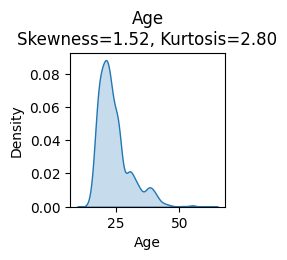

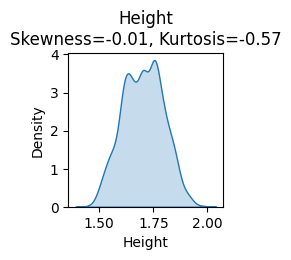

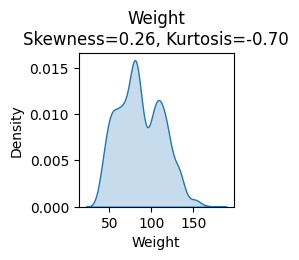

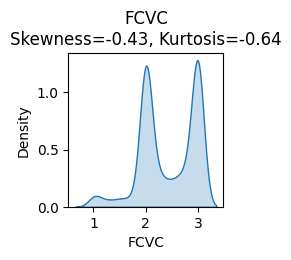

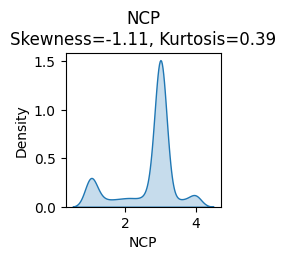

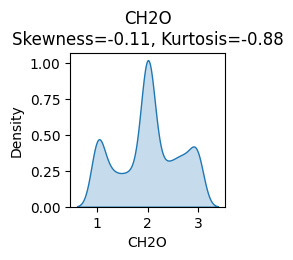

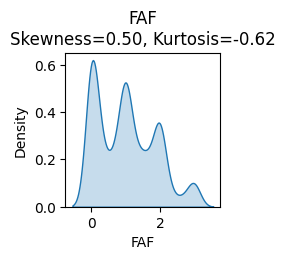

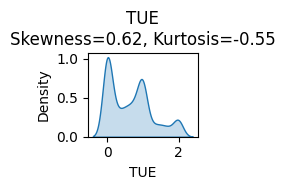

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in df_numerical.columns:
    plt.figure(figsize=(2,2))
    sns.kdeplot(
        data=df_numerical,
        x=col,
        fill=True
    )
    plt.title(
        f"{col}\nSkewness={df_numerical[col].skew():.2f}, "
        f"Kurtosis={df_numerical[col].kurtosis():.2f}"
    )
plt.tight_layout()
plt.xlabel(col)
plt.ylabel("Density")
plt.show()

/tmp/ipykernel_13105/3977651806.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df_numerical,labels=df_numerical.columns)


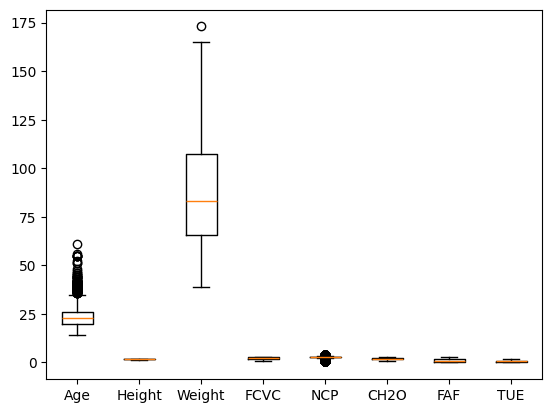

In [ ]:
plt.boxplot(df_numerical,labels=df_numerical.columns)
plt.show()

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.shape

(2087, 17)

In [ ]:
df['NObeyesdad'].value_counts()

,count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_II,290
Normal_Weight,282
Overweight_Level_I,276
Insufficient_Weight,267


In [ ]:
df_objects=df.select_dtypes(include=['object'])

In [ ]:
df['Gender'] = df['Gender'].map({
    'Female': 0,
    'Male': 1
})

df['family_history_with_overweight'] = df['family_history_with_overweight'].map({
    'no': 0,
    'yes': 1
})

df['FAVC'] = df['FAVC'].map({
    'no': 0,
    'yes': 1
})

df['CAEC'] = df['CAEC'].map({
    'no': 0,
    'Sometimes': 1,
    'Frequently': 2,
    'Always': 3
})

df['SMOKE'] = df['SMOKE'].map({
    'no': 0,
    'yes': 1
})

df['SCC'] = df['SCC'].map({
    'no': 0,
    'yes': 1
})

df['CALC'] = df['CALC'].map({
    'no': 0,
    'Sometimes': 1,
    'Frequently': 2,
    'Always': 3
})

df['MTRANS'] = df['MTRANS'].map({
    'Walking': 0,
    'Bike': 1,
    'Motorbike': 2,
    'Public_Transportation': 3,
    'Automobile': 4
})

df['NObeyesdad'] = df['NObeyesdad'].map({
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
})

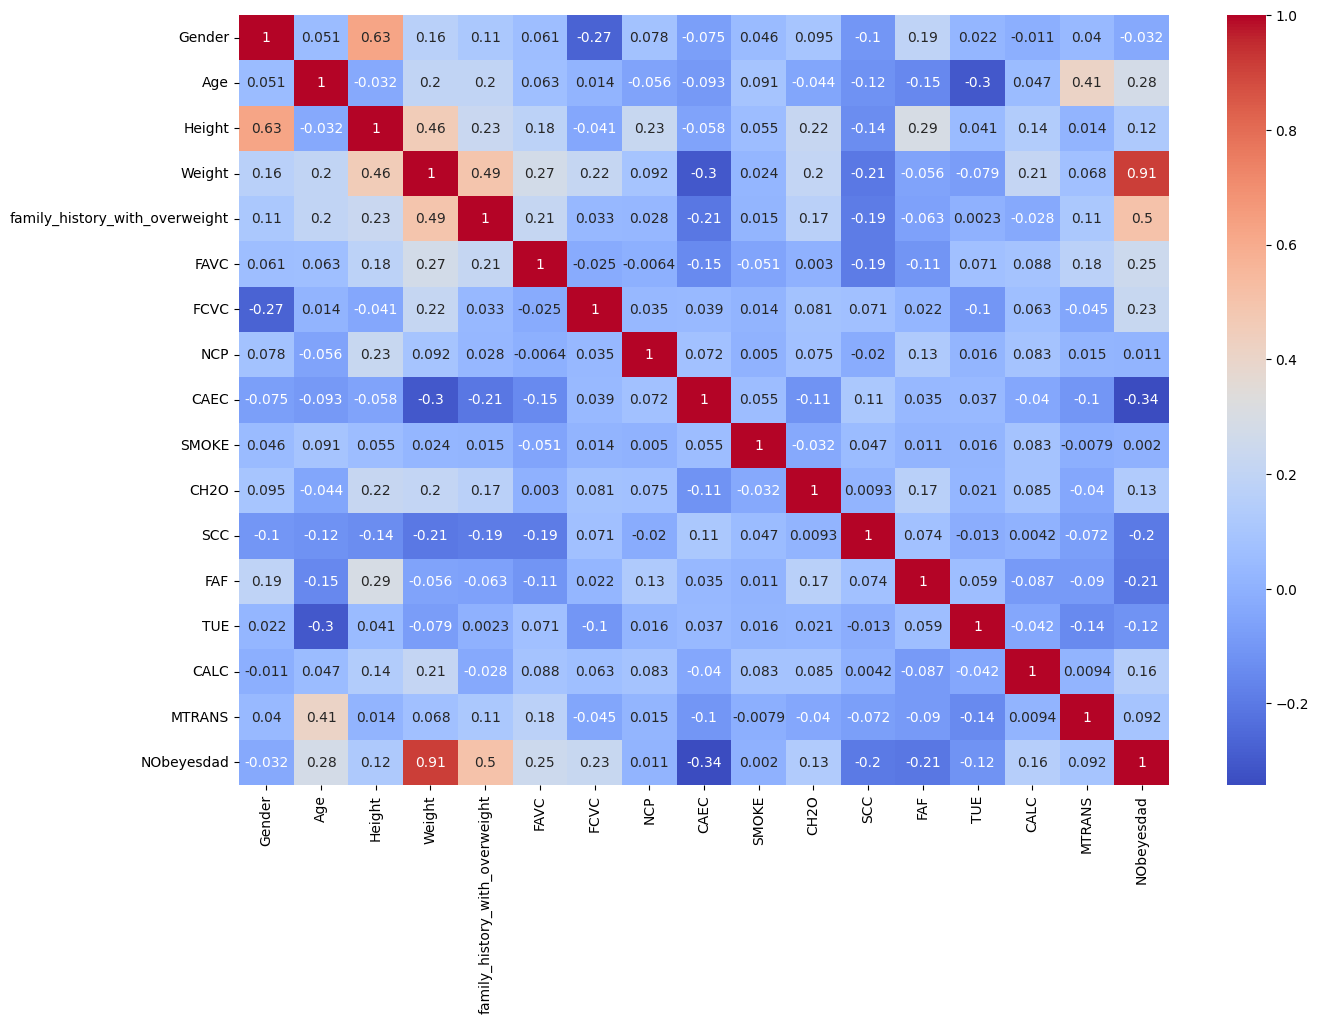

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')
plt.show()

In [ ]:
df_numerical=df.select_dtypes(include=['int64','float64'])
df_numerical.skew()
df_numerical.kurtosis()

,0
Gender,-2.001653
Age,2.740113
Height,-0.558172
Weight,-0.705464
family_history_with_overweight,0.934883
FAVC,3.732065
FCVC,-0.623084
NCP,0.534811
CAEC,5.797326
SMOKE,42.558120


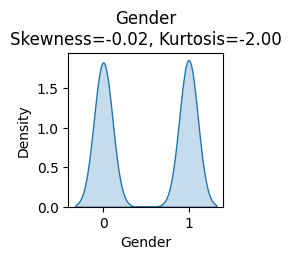

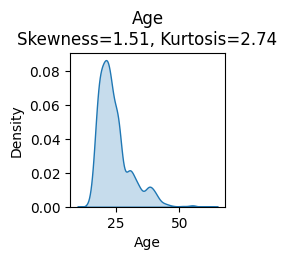

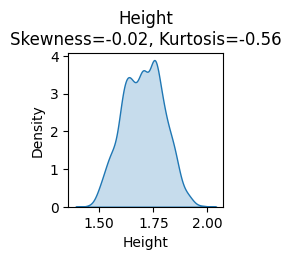

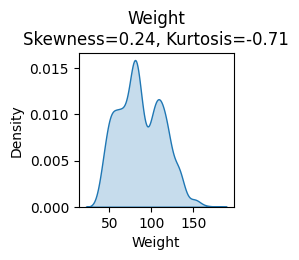

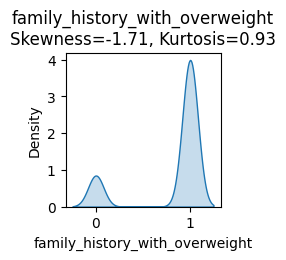

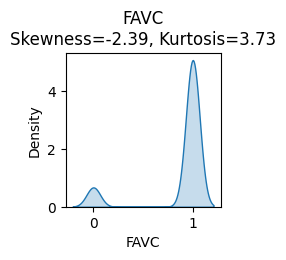

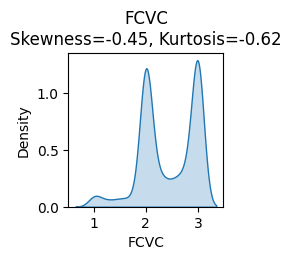

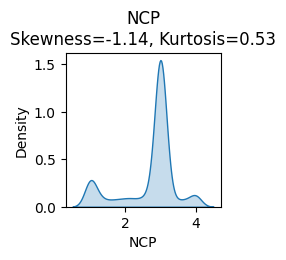

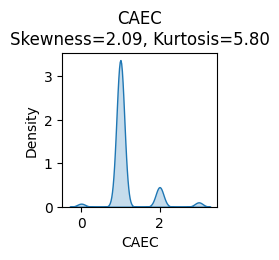

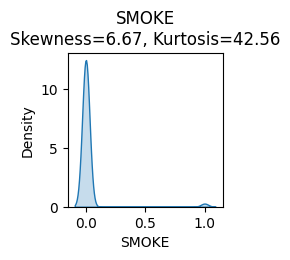

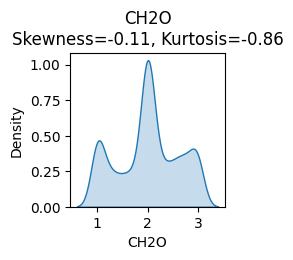

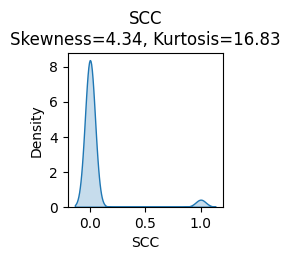

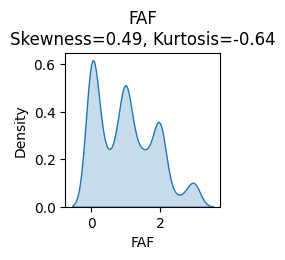

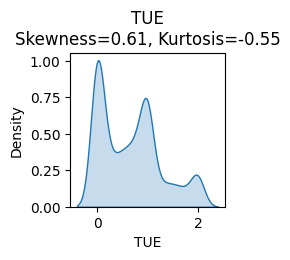

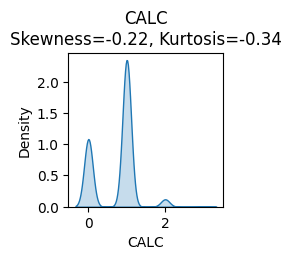

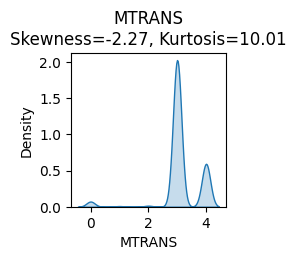

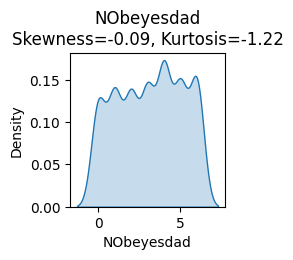

In [ ]:
for col in df_numerical.columns:
    plt.figure(figsize=(2,2))
    sns.kdeplot(
        data=df_numerical,
        x=col,
        fill=True
    )
    plt.title(
        f"{col}\nSkewness={df_numerical[col].skew():.2f}, "
        f"Kurtosis={df_numerical[col].kurtosis():.2f}"
    )
plt.xlabel(col)
plt.ylabel("Density")
plt.show()

In [ ]:
df['BMI']=df['Weight']/(df['Height']**2)

In [ ]:
x=df.drop('NObeyesdad',axis=1)
y=df['NObeyesdad']

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}
trained_models = {}
print("=== MODEL PERFORMANCE COMPARISON ===\n")
for name, model in models.items():
    model.fit(x_train, y_train)
    y_train_pred = model.predict(x_train)
    train_acc = accuracy_score(y_train, y_train_pred)
    y_test_pred = model.predict(x_test)
    test_acc = accuracy_score(y_test, y_test_pred)
    trained_models[name] = model
    print(f"Model: {name}")
    print(f"  - Training Accuracy: {train_acc * 100:.2f}%")
    print(f"  - Testing Accuracy: {test_acc * 100:.2f}%\n")

=== MODEL PERFORMANCE COMPARISON ===

Model: Random Forest
  - Training Accuracy: 100.00%
  - Testing Accuracy: 98.80%

Model: Gradient Boosting
  - Training Accuracy: 100.00%
  - Testing Accuracy: 98.33%

Model: XGBoost
  - Training Accuracy: 100.00%
  - Testing Accuracy: 98.80%

Model: Decision Tree
  - Training Accuracy: 100.00%
  - Testing Accuracy: 96.89%

Model: KNN
  - Training Accuracy: 96.64%
  - Testing Accuracy: 94.74%



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(x_train,y_train)
y_pred=rf.predict(x_test)
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Classification Report:\n",classification_report(y_test,y_pred))

Accuracy: 0.9880382775119617
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       0.97      1.00      0.98        57
           2       1.00      0.95      0.97        55
           3       0.98      1.00      0.99        58
           4       1.00      1.00      1.00        70
           5       0.98      0.98      0.98        60
           6       0.98      0.98      0.98        65

    accuracy                           0.99       418
   macro avg       0.99      0.99      0.99       418
weighted avg       0.99      0.99      0.99       418



In [ ]:
Gender = int(input("Gender (Male=1, Female=0): "))
Age = float(input("Age: "))
Height = float(input("Height (meters): "))
Weight = float(input("Weight (kg): "))
family_history = int(input("Family History of Overweight (Yes=1, No=0): "))
FAVC = int(input("Frequent High Calorie Food (Yes=1, No=0): "))
FCVC = float(input("Vegetable Consumption Frequency (1-3): "))
NCP = float(input("Number of Main Meals: "))
CAEC = int(input("Food Between Meals (No=0, Sometimes=1, Frequently=2, Always=3): "))
SMOKE = int(input("Smoking (Yes=1, No=0): "))
CH2O = float(input("Water Consumption (1-3): "))
SCC = int(input("Monitor Calories (Yes=1, No=0): "))
FAF = float(input("Physical Activity Frequency (0-3): "))
TUE = float(input("Technology Usage Time (0-2): "))
CALC = int(input("Alcohol Consumption (No=0, Sometimes=1, Frequently=2, Always=3): "))
MTRANS = int(input("Transport (Walking=0, Bike=1, Motorbike=2, Public Transport=3, Automobile=4): "))

Gender (Male=1, Female=0): 1
Age: 20
Height (meters): 1.722
Weight (kg): 57
Family History of Overweight (Yes=1, No=0): 0
Frequent High Calorie Food (Yes=1, No=0): 0
Vegetable Consumption Frequency (1-3): 1
Number of Main Meals: 1
Food Between Meals (No=0, Sometimes=1, Frequently=2, Always=3): 1
Smoking (Yes=1, No=0): 0
Water Consumption (1-3): 3
Monitor Calories (Yes=1, No=0): 0
Physical Activity Frequency (0-3): 1
Technology Usage Time (0-2): 1
Alcohol Consumption (No=0, Sometimes=1, Frequently=2, Always=3): 0
Transport (Walking=0, Bike=1, Motorbike=2, Public Transport=3, Automobile=4): 0


In [ ]:
BMI = Weight / (Height ** 2)

user_data = [[
    Gender,
    Age,
    Height,
    Weight,
    family_history,
    FAVC,
    FCVC,
    NCP,
    CAEC,
    SMOKE,
    CH2O,
    SCC,
    FAF,
    TUE,
    CALC,
    MTRANS,
    BMI
]]

In [ ]:
prediction = rf.predict(user_data)
print("Predicted Class:", prediction[0])

Predicted Class: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
obesity_labels = {
    0: "Insufficient Weight",
    1: "Normal Weight",
    2: "Overweight Level I",
    3: "Overweight Level II",
    4: "Obesity Type I",
    5: "Obesity Type II",
    6: "Obesity Type III"
}
obesity_level = obesity_labels[prediction[0]]
print("Predicted Obesity Level:", obesity_level)

Predicted Obesity Level: Normal Weight


In [ ]:
import google.generativeai as genai
genai.configure(api_key="YOUR_API_KEY")
model=genai.GenerativeModel('models/gemini-3.1-flash-lite')
prompt =f"""
You are an experienced doctor, nutritionist, fitness coach and lifestyle consultant.

A person has been predicted to have:

Obesity Level: {obesity_level}

Personal Details:
Age: {Age}
Height: {Height} m
Weight: {Weight} kg
BMI: {BMI}

Lifestyle Information:
Family History of Overweight: {'Yes' if family_history == 1 else 'No'}
Frequent High Calorie Food: {'Yes' if FAVC == 1 else 'No'}
Vegetable Consumption Score: {FCVC}
Meals Per Day: {NCP}
Snacking Frequency: {CAEC}
Smoking: {'Yes' if SMOKE == 1 else 'No'}
Water Consumption: {CH2O}
Physical Activity: {FAF}
Technology Usage: {TUE}
Alcohol Consumption: {CALC}
Transportation Mode: {MTRANS}

Provide your response in exactly this format:

# Health Assessment
(health risks)

# BMI Analysis
(current BMI category and explanation)

# Recommended Daily Calories
(calorie target)

# Diet Plan (only include veg)
Give general options for what to eat do not specify any time of day
1:
2:
3:
4:
5:

# Exercise Plan
Monday:
Tuesday:
Wednesday:
Thursday:
Friday:
Saturday:
Sunday:

# Foods To Avoid
(list)

# Lifestyle Changes
(list)

# Expected Improvement
(what can happen in 1 month, 3 months, and 6 months if recommendations are followed)

Keep the advice practical and easy to follow."""


In [ ]:
response = model.generate_content(prompt)
print(response.text)

# Health Assessment
Your primary health risk is **nutritional insufficiency and metabolic strain** due to eating only one meal per day. While your BMI is in the "Normal" range, your habits suggest a restricted caloric intake that can lead to muscle wasting, nutrient deficiencies, fatigue, and hormonal imbalances. Your low vegetable consumption further limits essential micronutrients.

# BMI Analysis
Your BMI is 19.22. This is classified as **Normal Weight**. However, you are on the lower end of the healthy range. Your health focus should shift from weight management to body recomposition—increasing muscle mass and stabilizing metabolic health through consistent nutrition rather than weight loss.

# Recommended Daily Calories
2,100 – 2,300 calories per day (focused on nutrient density to support a healthy weight and activity level).

# Diet Plan (only include veg)
1: Spinach and kale salad with chickpeas, avocado, olive oil, and toasted sunflower seeds.
2: Roasted sweet potatoes with st